# Análise de evasão de colaboradores

Este notebook consome exclusivamente a camada **Gold**. Antes de executá-lo, rode `python src/run_pipeline.py` a partir da raiz do projeto.

Pergunta norteadora: quais grupos apresentam maior taxa de desligamento e quais fatores operacionais merecem investigação? 

In [1]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
GOLD = ROOT / 'data' / 'gold' / 'evasao_colaboradores.parquet'
assert GOLD.exists()
con = duckdb.connect()
con.execute(f"CREATE OR REPLACE VIEW evasao AS SELECT * FROM read_parquet('{GOLD.as_posix()}')")
sns.set_theme(style='whitegrid', palette='deep')

In [2]:
resumo = con.sql("""
    SELECT
        COUNT(*) AS colaboradores,
        SUM(desligado_flag) AS desligados,
        ROUND(100.0 * AVG(desligado_flag), 2) AS taxa_evasao_pct,
        ROUND(AVG(score_satisfacao), 2) AS satisfacao_media,
        ROUND(AVG(horas_extras_mes), 1) AS horas_extras_media
    FROM evasao
""").df()
display(resumo)

qualidade = pd.read_json(ROOT / 'reports' / 'data_quality_report.json', typ='series')
display(qualidade)

,colaboradores,desligados,taxa_evasao_pct,satisfacao_media,horas_extras_media
0,650,177.0,27.23,3.48,20.9


executado_em                                                      2026-07-21
metricas                   {'linhas_entrada': 650, 'duplicados_exatos_rem...
linhas_silver                                                            650
data_referencia_analise                                           2026-01-01
linhas_gold                                                              650
taxa_evasao                                                           0.2723
dtype: object

Query para ter uma visão geral dos dados + arquivo json que é gerado quando construímos a camada silver.

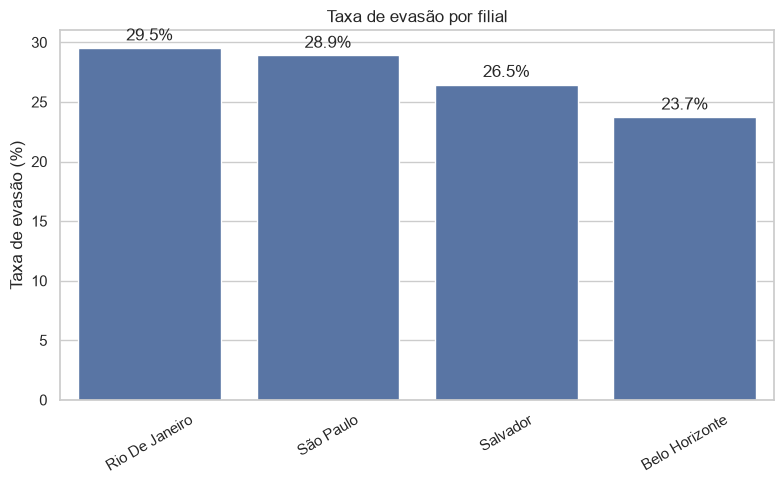

In [4]:
fig, ax = plt.subplots(figsize=(8,5))

def taxa(coluna):
    consulta = f"""
    SELECT
        {coluna} AS grupo,
        100.0 * AVG(desligado_flag) AS taxa
    FROM evasao
    GROUP BY 1
    """
    return con.sql(consulta).df().sort_values('taxa', ascending=False)

sns.barplot(
    data=taxa('cidade'),
    x='grupo',
    y='taxa',
    ax=ax
)

ax.set_title('Taxa de evasão por filial')
ax.set_xlabel('')
ax.set_ylabel('Taxa de evasão (%)')
ax.tick_params(axis='x', rotation=30)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.tight_layout()

Iniciei a análise tentando buscar alguma anomalia ao tentar separar por filial mas não encontrei nada muito diferente.

In [3]:
por_grupo = con.sql("""
    SELECT 'Departamento' AS dimensao, nome_departamento AS grupo, COUNT(*) AS colaboradores,
           ROUND(100.0 * AVG(desligado_flag), 2) AS taxa_de_evasao
    FROM evasao GROUP BY 1, 2
    UNION ALL
    SELECT 'Nível', nivel, COUNT(*), ROUND(100.0 * AVG(desligado_flag), 2)
    FROM evasao GROUP BY 1, 2
    UNION ALL
    SELECT 'Faixa de satisfação', faixa_satisfacao, COUNT(*), ROUND(100.0 * AVG(desligado_flag), 2)
    FROM evasao GROUP BY 1, 2
    UNION ALL
    SELECT 'Horas extras', faixa_horas_extras, COUNT(*), ROUND(100.0 * AVG(desligado_flag), 2)
    FROM evasao GROUP BY 1, 2
    ORDER BY taxa_de_evasao DESC
""").df()
display(por_grupo.query('colaboradores >= 15'))

,dimensao,grupo,colaboradores,taxa_de_evasao
0,Nível,Pleno,246,47.15
1,Faixa de satisfação,"Baixa (1-2,5)",165,44.24
2,Departamento,Trabalhista,170,43.53
3,Horas extras,Alta (26+),170,43.53
4,Departamento,Tributário,182,27.47
5,Faixa de satisfação,"Alta (3,6-5)",404,21.53
6,Horas extras,Media (11-25),284,21.48
7,Horas extras,Baixa (0-10),196,21.43
8,Faixa de satisfação,"Media (2,6-3,5)",81,20.99
9,Nível,Sênior,95,18.95


Essa query é responsável por gerar todos cenários possíveis entre as dimensões para encontrar quais subgrupos possuem as maiores taxas de evasão.
A maior concentração de evasão está entre funcionários plenos, baixa satisfação, grande quantidade de horas extras e no departamento trabalhista

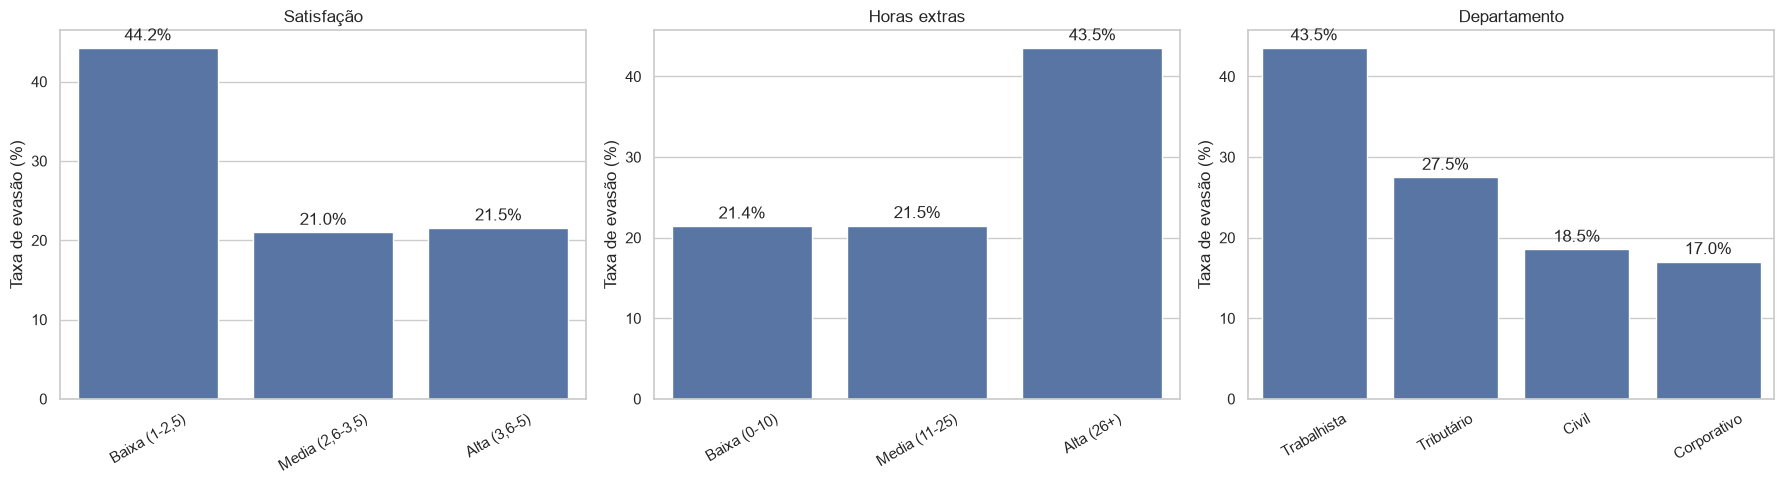

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ordem_sat = ['Baixa (1-2,5)', 'Media (2,6-3,5)', 'Alta (3,6-5)']
ordem_horas = ['Baixa (0-10)', 'Media (11-25)', 'Alta (26+)']

def taxa(coluna, ordem=None):
    consulta = f'SELECT {coluna} AS grupo, 100.0 * AVG(desligado_flag) AS taxa FROM evasao GROUP BY 1'
    resultado = con.sql(consulta).df()
    if ordem: resultado['grupo'] = pd.Categorical(resultado['grupo'], categories=ordem, ordered=True); resultado = resultado.sort_values('grupo')
    return resultado

sns.barplot(data=taxa('faixa_satisfacao', ordem_sat), x='grupo', y='taxa', ax=axes[0])
sns.barplot(data=taxa('faixa_horas_extras', ordem_horas), x='grupo', y='taxa', ax=axes[1])
sns.barplot(data=taxa('nome_departamento').sort_values('taxa', ascending=False), x='grupo', y='taxa', ax=axes[2])
for ax in axes:
    ax.set(xlabel='', ylabel='Taxa de evasão (%)'); ax.tick_params(axis='x', rotation=30)
    for container in ax.containers: ax.bar_label(container, fmt='%.1f%%', padding=3)
axes[0].set_title('Satisfação'); axes[1].set_title('Horas extras'); axes[2].set_title('Departamento')
plt.tight_layout()

Plotagem de gráfico para visualizar o que já tinha sido constatado anteriormente.

In [39]:
prioridades = con.sql("""
    SELECT nome_departamento, faixa_satisfacao, faixa_horas_extras, COUNT(*) AS base,
           ROUND(100 * AVG(desligado_flag), 1) AS taxa_de_evasao
    FROM evasao
    GROUP BY 1, 2, 3 HAVING COUNT(*) >= 10
    ORDER BY taxa_de_evasao DESC, base DESC
""").df()
display(prioridades)


,nome_departamento,faixa_satisfacao,faixa_horas_extras,base,taxa_de_evasao
0,Trabalhista,"Baixa (1-2,5)",Alta (26+),165,44.2
1,Tributário,"Alta (3,6-5)",Media (11-25),99,28.3
2,Tributário,"Alta (3,6-5)",Baixa (0-10),57,26.3
3,Corporativo,"Media (2,6-3,5)",Media (11-25),14,21.4
4,Tributário,"Media (2,6-3,5)",Media (11-25),20,20.0
5,Civil,"Alta (3,6-5)",Baixa (0-10),51,19.6
6,Civil,"Alta (3,6-5)",Media (11-25),72,18.1
7,Corporativo,"Alta (3,6-5)",Baixa (0-10),60,16.7
8,Corporativo,"Alta (3,6-5)",Media (11-25),60,16.7
9,Civil,"Media (2,6-3,5)",Media (11-25),19,15.8


Ao gerar todos os subgrupos possíveis utilizando faixa de satisfação, departamento e faixa de horas extras é possível perceber que um padrão se destaca no quesito taxa de evasão, reiterando o que foi dito anteriormente e mostrando que existe realmente uma ligação entre esses dados, esse padrão é o combo: setor trabalhista + baixa satisfação + alta carga horária.

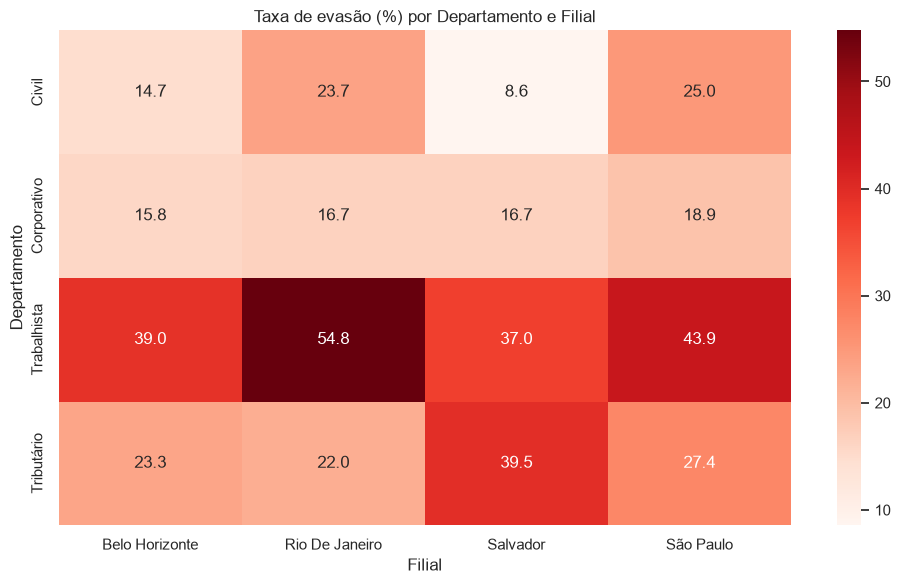

In [40]:
consulta = """
SELECT
    cidade,
    nome_departamento,
    ROUND(100*AVG(desligado_flag),2) AS taxa
FROM evasao
GROUP BY 1,2
"""

heat = con.sql(consulta).df()

pivot = heat.pivot(
    index="nome_departamento",
    columns="cidade",
    values="taxa"
)

plt.figure(figsize=(10,6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".1f",
    cmap="Reds"
)

plt.title("Taxa de evasão (%) por Departamento e Filial")
plt.xlabel("Filial")
plt.ylabel("Departamento")

plt.tight_layout()

Resolvi cruzar dados com as filiais e mesmo dentro do departamento trabalhista existe uma filial que se destaca, o Rio de Janeiro.

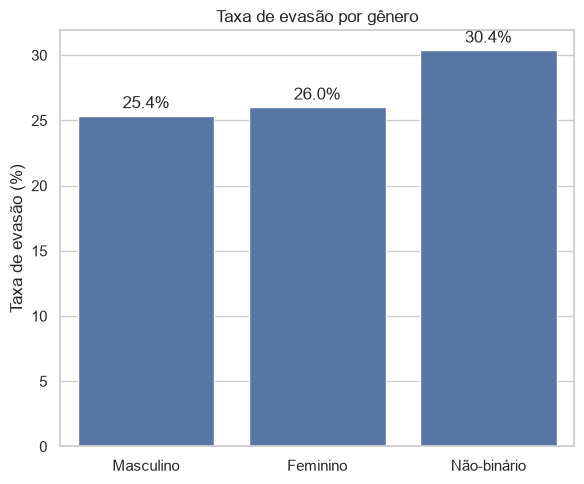

In [41]:
fig, ax = plt.subplots(figsize=(6,5))

def taxa(coluna):
    consulta = f"""
    SELECT
        {coluna} AS grupo,
        100.0 * AVG(desligado_flag) AS taxa
    FROM evasao
    GROUP BY 1
    """
    return con.sql(consulta).df()

sns.barplot(
    data=taxa('genero'),
    x='grupo',
    y='taxa',
    ax=ax
)

ax.set_title('Taxa de evasão por gênero')
ax.set_xlabel('')
ax.set_ylabel('Taxa de evasão (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.tight_layout()

É de conhecimento geral que o gênero de uma pessoa pode influenciar a maneira como ela é tratada, por isso decidi cruzar a taxa de evasão com o gênero. 

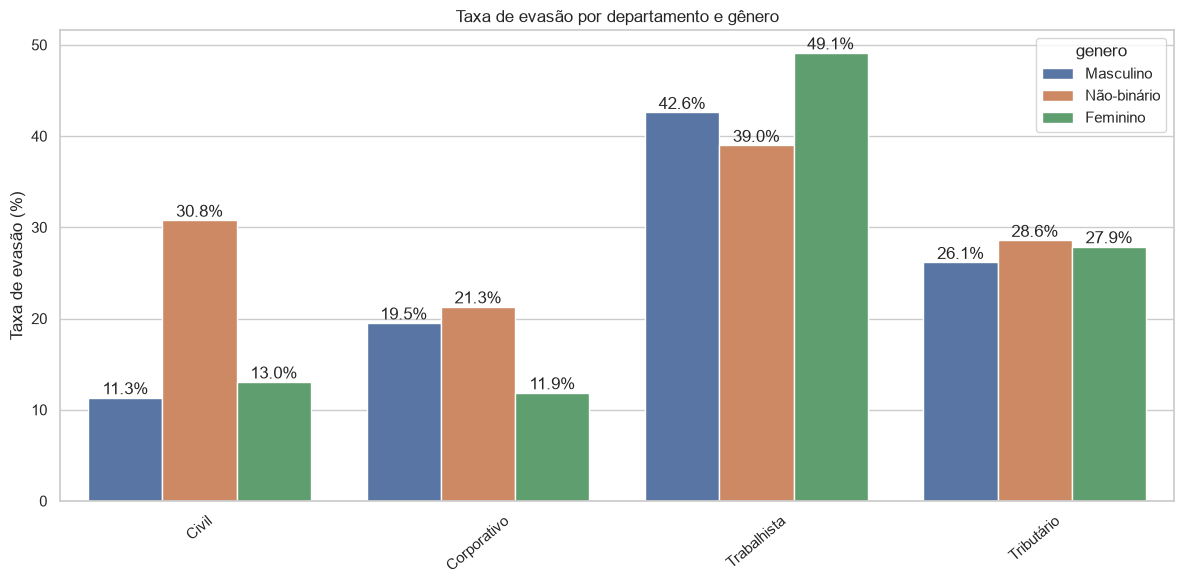

In [42]:
consulta = """
SELECT
    nome_departamento,
    genero,
    ROUND(100*AVG(desligado_flag),2) AS taxa
FROM evasao
GROUP BY 1,2
"""

dados = con.sql(consulta).df()

plt.figure(figsize=(12,6))

sns.barplot(
    data=dados,
    x="nome_departamento",
    y="taxa",
    hue="genero"
)

plt.xticks(rotation=40)
plt.ylabel("Taxa de evasão (%)")
plt.xlabel("")
plt.title("Taxa de evasão por departamento e gênero")

for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt="%.1f%%")

plt.tight_layout()

Percebi que mesmo sendo uma variação que considerei pequena, notei que a taxa de evasão de pessoas não-binárias pareceu um pouco maior, então decidi cruzar dados entre taxa de evasão, departamento e gênero para ver se eu encontrava alguma anomalia e notei que essas pessoas tinha uma taxa de evasão muito grande quando estão no departamento Civil. Decidi então verificar por filial para saber se isso é uma padrão do departamento ou não.

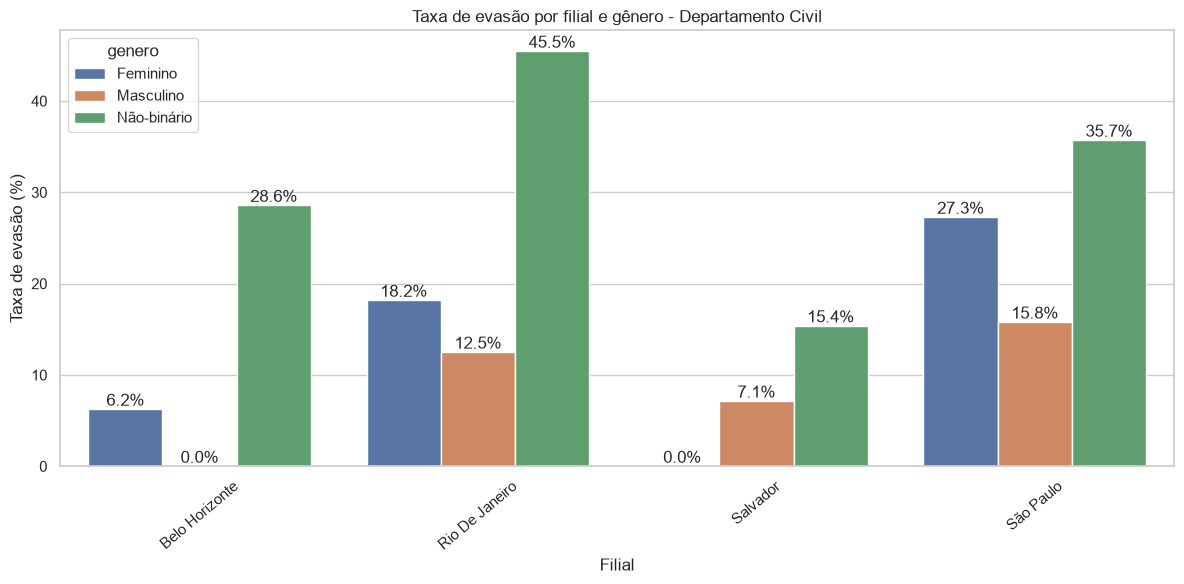

In [43]:
consulta = """
SELECT
    cidade,
    genero,
    ROUND(100 * AVG(desligado_flag), 2) AS taxa
FROM evasao
WHERE nome_departamento = 'Civil'
GROUP BY 1,2
ORDER BY 1,2
"""

dados = con.sql(consulta).df()

plt.figure(figsize=(12,6))

sns.barplot(
    data=dados,
    x="cidade",
    y="taxa",
    hue="genero"
)

plt.xticks(rotation=40)
plt.ylabel("Taxa de evasão (%)")
plt.xlabel("Filial")
plt.title("Taxa de evasão por filial e gênero - Departamento Civil")

for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()

Ao aproximar dos dados é possível perceber que tanto em Belo Horizente quanto no Rio de Janeiro a taxa de evasão de pessoas não-binárias destoa em relação aos outros gêneros.

In [47]:
con.sql("""
SELECT
    cidade,
    genero,
    COUNT(*) AS quantidade,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY cidade), 2) AS percentual_da_filial
FROM evasao
WHERE nome_departamento = 'Civil'
  AND cidade IN ('Belo Horizonte', 'Rio De Janeiro')
GROUP BY cidade, genero
ORDER BY cidade, genero;
""").df()

,cidade,genero,quantidade,percentual_da_filial
0,Belo Horizonte,Feminino,16,47.06
1,Belo Horizonte,Masculino,4,11.76
2,Belo Horizonte,Não-binário,14,41.18
3,Rio De Janeiro,Feminino,11,28.95
4,Rio De Janeiro,Masculino,16,42.11
5,Rio De Janeiro,Não-binário,11,28.95


Me surgiu a dúvida de que isso poderia acontecer devido de uma possível distorção por causa da quantidade de pessoas não-binárias, mas isso se provou falso porque nos dados utilizados as pessoas estão  relativamente bem distribuídas em relação ao gênero, ou seja, a evasão de pessoas não-binárias é algo que deve ser investigada mais a fundo.